# Credit Card Fraud Detection
Oasis Infobyte Internship Program (OIBSIP), Data Analytics track, Task 3
This notebook builds a machine learning pipeline to detect fraudulent credit card transactions in a heavily imbalanced dataset.

## Loading the Data and Checking Class Imbalance
The data is the Credit Card Fraud Detection dataset from Kaggle, collected by Worldline and the Machine Learning Group of ULB. It has 284,807 transactions made by European cardholders over two days in September 2013. V1 to V28 are anonymous components, Amount is the transaction amount and Class is 1 for fraud.

In [1]:
# Download the dataset from Kaggle (needs internet, runs once)
import os
import kagglehub

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Files downloaded to:", path)
print(os.listdir(path))

C:\Users\ADMIN\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Files downloaded to: C:\Users\ADMIN\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3
['creditcard.csv']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load the dataset from the folder kagglehub downloaded it to
df = pd.read_csv(os.path.join(path, "creditcard.csv"))

# Rows and columns
print("Shape:", df.shape)

# Column names, data types and non-null counts
df.info()

Shape: (284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V

In [3]:
# First five rows to see what the data looks like
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
# Missing values and duplicate rows
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 1081


In [5]:
# Class counts and percentages (Class: 0 = not fraud, 1 = fraud)
class_counts = df["Class"].value_counts()
class_percent = df["Class"].value_counts(normalize=True) * 100

print(class_counts)
print()
print(class_percent.round(4))

Class
0    284315
1       492
Name: count, dtype: int64

Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


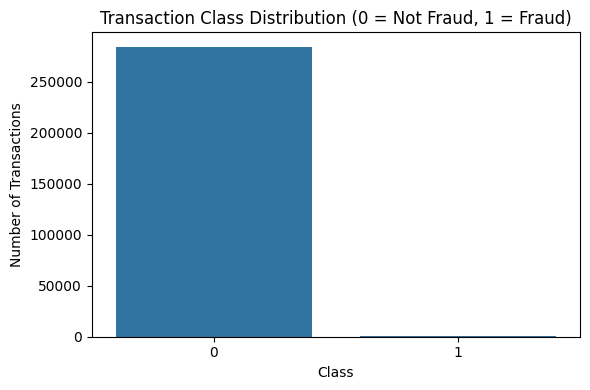

In [24]:
# Bar chart of the class counts
plt.figure(figsize=(6, 4))
sns.countplot(x="Class", data=df)
plt.title("Transaction Class Distribution (0 = Not Fraud, 1 = Fraud)")
plt.xlabel("Class")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

Fraud is 492 of the 284,807 transactions, about 0.17% (roughly 1 in 580). The fraud bar is too small to see next to the normal one.

## Checking Duplicate Rows
The data has 1081 rows that are copies of another row. If these stay in, the same transaction could end up in both the training set and the test set, and the test scores would look better than they really are. Before deciding what to do, I check how many of the duplicates are fraud cases.

In [7]:
# Mark every row that is a duplicate
dup_mark = df.duplicated()

# How many duplicates are fraud and how many are not
print("Duplicate rows by class:")
print(df[dup_mark]["Class"].value_counts())
print()



Duplicate rows by class:
Class
0    1062
1      19
Name: count, dtype: int64



## Investigating the Duplicate RowsThe data contains 1081 rows that are exact copies of another row. Before removing anything, I check how the duplicates are spread: how many copies each transaction has, whether any identical transactions carry different labels, and what the duplicated fraud rows look like..

In [8]:
# Every column except the label
feature_cols = [c for c in df.columns if c != "Class"]

# Every row that is part of a duplicate group, including the first copy
# (keep=False marks all copies, not just the later ones)
dup_all = df[df.duplicated(keep=False)]

# how many copies does each duplicated transaction have?
group_sizes = dup_all.groupby(list(df.columns)).size()
print("Copies per duplicated transaction:")
print(group_sizes.value_counts().sort_index())
print()

# do any identical feature rows carry different labels?
label_check = df.groupby(feature_cols)["Class"].nunique()
print("Feature combinations with conflicting labels:", (label_check > 1).sum())
print()

# a look at some duplicated rows (selected columns only)
print("Sample of duplicated rows:")
print(dup_all[["Time", "V1", "V2", "Amount", "Class"]].sort_values("Time").head(10))
print()

# the duplicated fraud rows
print("Duplicated fraud rows:")
print(dup_all[dup_all["Class"] == 1][["Time", "Amount", "Class"]].sort_values("Time"))

Copies per duplicated transaction:
2     611
3      66
4      81
5      10
6       1
9       2
18      2
Name: count, dtype: int64

Feature combinations with conflicting labels: 0

Sample of duplicated rows:
      Time        V1        V2  Amount  Class
32    26.0 -0.529912  0.873892    6.14      0
33    26.0 -0.529912  0.873892    6.14      0
34    26.0 -0.535388  0.865268    1.77      0
35    26.0 -0.535388  0.865268    1.77      0
112   74.0  1.038370  0.127486    1.18      0
113   74.0  1.038370  0.127486    1.18      0
114   74.0  1.038370  0.127486    1.18      0
115   74.0  1.038370  0.127486    1.18      0
220  145.0 -2.420413  1.947885    6.00      0
221  145.0 -2.420413  1.947885    6.00      0

Duplicated fraud rows:
            Time  Amount  Class
102441   68207.0    1.00      1
102442   68207.0    1.00      1
102443   68207.0    1.00      1
102444   68207.0    1.00      1
102445   68207.0    1.00      1
102446   68207.0    1.00      1
141257   84204.0    0.00      1
141258

## Decision on Duplicate Rows
The data has 1081 extra copies of rows, and 19 of them are fraud cases. No identical rows have different labels. I cannot tell if these are repeated records or real transactions made in the same second, so I removed them to stop the same transaction landing in both the training and test sets. That leaves 283,726 rows and 473 fraud cases (0.1667%). The original `df` is kept and the cleaned data is `df_clean`. One limitation is that my results will not match work that uses all 284,807 rows.

In [9]:
# Remove the duplicates into a new dataframe (the original df stays unchanged)
df_clean = df.drop_duplicates().copy()

# Shape and class balance after removing duplicates
print("Shape after removing duplicates:", df_clean.shape)
print()
print(df_clean["Class"].value_counts())
print()
print((df_clean["Class"].value_counts(normalize=True) * 100).round(4))

Shape after removing duplicates: (283726, 31)

Class
0    283253
1       473
Name: count, dtype: int64

Class
0    99.8333
1     0.1667
Name: proportion, dtype: float64


## Exploring Transaction Amounts
Comparing the amounts of fraud and normal transactions. The amounts are very uneven, so I use a log scale in the charts.

In [10]:
# Summary statistics of Amount for each class
print(df_clean.groupby("Class")["Amount"].describe().round(2))
print()

# Transactions with an Amount of exactly 0, by class
print("Zero amount transactions by class:")
print(df_clean[df_clean["Amount"] == 0]["Class"].value_counts())

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87

Zero amount transactions by class:
Class
0    1783
1      25
Name: count, dtype: int64


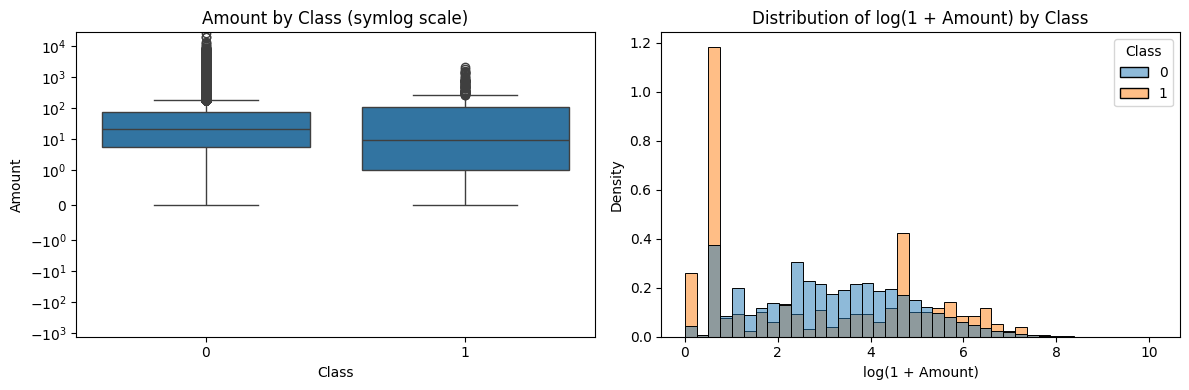

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: boxplot of Amount by class. A symlog scale is used because the
# amounts are very skewed and some are exactly 0 (a plain log scale cannot show 0)
sns.boxplot(x="Class", y="Amount", data=df_clean, ax=axes[0])
axes[0].set_yscale("symlog", linthresh=1)
axes[0].set_title("Amount by Class (symlog scale)")

# Right: histogram of log(1 + Amount). density with common_norm=False scales
# each class to its own total, so the shapes can be compared even though
# there are far fewer fraud cases
sns.histplot(x=np.log1p(df_clean["Amount"]), hue=df_clean["Class"],
             stat="density", common_norm=False, bins=40, ax=axes[1])
axes[1].set_title("Distribution of log(1 + Amount) by Class")
axes[1].set_xlabel("log(1 + Amount)")

plt.tight_layout()
plt.savefig("amount_distribution.png", dpi=150)
plt.show()

Fraud transactions tend to be smaller than normal ones (median 9.82 against 22.00), and 5.3% of frauds have an amount of exactly 0 against 0.6% of normal transactions. The two classes overlap a lot, so Amount alone cannot separate them.

## Transaction Timing Analysis
Time represents seconds elapsed since the first transaction, so this analysis groups transactions by elapsed hour rather than true clock time.

Time range in hours: 0.0 to 48.0

      Transactions  Frauds  FraudRate%
Hour                                  
0             7647       6       0.078
1             4208      10       0.238
2             3308      48       1.451
3             3487      17       0.488
4             2204      23       1.044
5             2988      11       0.368
6             4082       9       0.220
7             7233      23       0.318
8            10232       9       0.088
9            15767      16       0.101
10           16548       8       0.048
11           16781      53       0.316
12           15378      17       0.111
13           15323      17       0.111
14           16520      23       0.139
15           16374      26       0.159
16           16396      22       0.134
17           16130      28       0.174
18           16959      28       0.165
19           15566      19       0.122
20           16705      18       0.108
21           17629      16       0.091
22           15378       9    

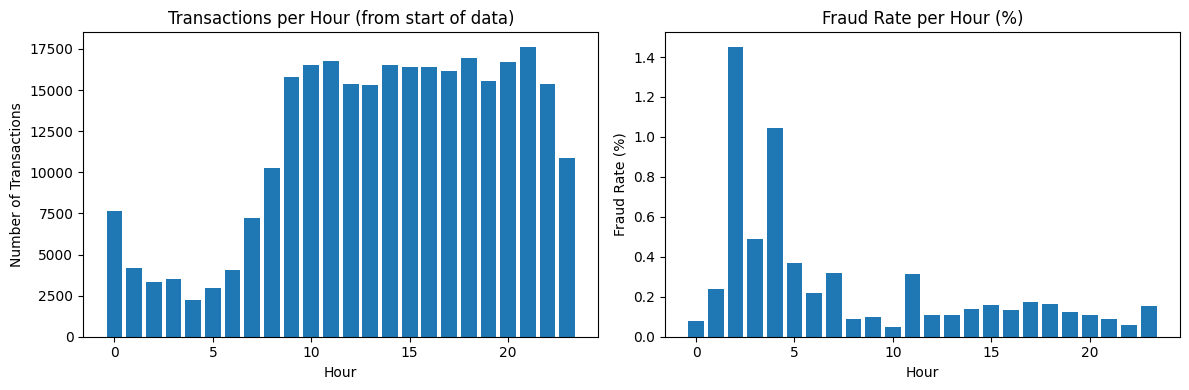

In [26]:
# How long the data covers, in hours
print("Time range in hours:", round(df_clean["Time"].min() / 3600, 2),
      "to", round(df_clean["Time"].max() / 3600, 2))
print()

# Hour of the 24 hour cycle, counted from the start of the data
hour = ((df_clean["Time"] // 3600) % 24).astype(int)

# Transactions, fraud cases and fraud rate for each hour
hour_table = (df_clean.assign(Hour=hour)
              .groupby("Hour")["Class"]
              .agg(Transactions="count", Frauds="sum"))
hour_table["FraudRate%"] = (hour_table["Frauds"] / hour_table["Transactions"] * 100).round(3)
print(hour_table)

# Charts: transaction volume and fraud rate by hour
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(hour_table.index, hour_table["Transactions"])
axes[0].set_title("Transactions per Hour (from start of data)")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Number of Transactions")

axes[1].bar(hour_table.index, hour_table["FraudRate%"])
axes[1].set_title("Fraud Rate per Hour (%)")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.savefig("hour_analysis.png", dpi=150)
plt.show()

Most transactions happen in hours 9 to 22 and volume drops in hours 1 to 7, which looks like a day and night cycle. Fraud rates are highest at hours 2 and 4 (1.45% and 1.04% against 0.17% overall), when volume is low. The data covers only two days, so this could be a few bursts, and I treat it as a hint and not a firm pattern.

In [13]:
# Most common amounts among fraud transactions
print(df_clean[df_clean["Class"] == 1]["Amount"].value_counts().head(8))

Amount
1.00     105
99.99     27
0.00      25
0.76      17
0.77      10
0.01       5
3.79       4
2.00       4
Name: count, dtype: int64




Only 473 of the 283,726 transactions are fraud, about 0.17%. If a model just said "not fraud" every time, “its accuracy would be 99.83% and never catch a single fraud. So I looked at recall and precision for the fraud class, plus F1, AUC-ROC and AUPRC. To show the problem, here is a model that never flags anything.

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

y_true = df_clean["Class"]

# a pretend model that says "not fraud" for every transaction
y_never_fraud = np.zeros(len(y_true), dtype=int)

print("Accuracy:", round(accuracy_score(y_true, y_never_fraud), 4))
print("Recall:", round(recall_score(y_true, y_never_fraud), 4))

# zero_division=0 just stops a warning, since this model flags nothing
print("Precision:", round(precision_score(y_true, y_never_fraud, zero_division=0), 4))

Accuracy: 0.9983
Recall: 0.0
Precision: 0.0


## Train and test split

I split the cleaned data 80/20. I used stratify so fraud cases show up in both parts in the same proportion. I droped Time because it is seconds since the start of the data. Amount is scaled with a scaler that learns only from the training part, so nothing from the test set leaks in.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# features and label (Time is dropped)
X = df_clean.drop(columns=["Class", "Time"])
y = df_clean["Class"]

# 80/20 split, stratified so both parts keep the same fraud share
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# scale Amount, learning the scaling from the training part only
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train["Amount"] = scaler.fit_transform(X_train[["Amount"]])
X_test["Amount"] = scaler.transform(X_test[["Amount"]])

print("Train:", X_train.shape, "frauds:", y_train.sum(), f"({y_train.mean() * 100:.4f}%)")
print("Test:", X_test.shape, "frauds:", y_test.sum(), f"({y_test.mean() * 100:.4f}%)")

Train: (226980, 29) frauds: 378 (0.1665%)
Test: (56746, 29) frauds: 95 (0.1674%)


## Handling the imbalance and training the models

I used class_weight="balanced" in both models. It makes a mistake on a fraud case count much more than a mistake on a normal one, so the models can't just ignore the fraud class. I did not use SMOTE, to keep it simple and avoid making fake fraud rows. The two models are Logistic Regression and Random Forest.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression with balanced class weights
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)
print("Logistic Regression trained")

# Random Forest with balanced class weights (this one can take a few minutes)
rf = RandomForestClassifier(
    n_estimators=100, max_depth=10, class_weight="balanced",
    n_jobs=-1, random_state=42
)
rf.fit(X_train, y_train)
print("Random Forest trained")

Logistic Regression trained
Random Forest trained


## Evaluating the models

I score both models on the test set with precision, recall and F1 for the fraud class, plus AUC-ROC and AUPRC. AUPRC is there because the dataset description recommends it for data this uneven. The predictions below use the default 0.5 cut off.

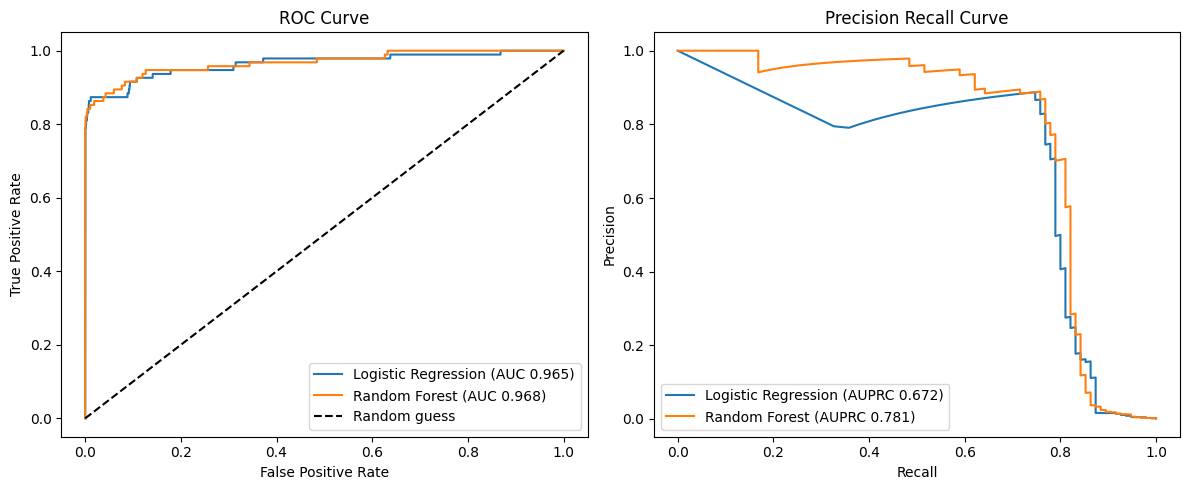

In [17]:
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score, average_precision_score)
models = {"Logistic Regression": log_reg, "Random Forest": rf}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})")

    # precision recall curve
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{name} (AUPRC {average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

axes[1].set_title("Precision Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.savefig("roc_pr_curves.png", dpi=150)
plt.show()

In [18]:
from sklearn.metrics import classification_report, confusion_matrix

models = {"Logistic Regression": log_reg, "Random Forest": rf}

for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    print("=====", name, "=====")
    print(classification_report(y_test, pred, digits=4))
    print("AUC-ROC:", round(roc_auc_score(y_test, proba), 4))
    print("AUPRC:", round(average_precision_score(y_test, proba), 4))
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(confusion_matrix(y_test, pred))
    print()


===== Logistic Regression =====
              precision    recall  f1-score   support

           0     0.9998    0.9751    0.9873     56651
           1     0.0557    0.8737    0.1047        95

    accuracy                         0.9750     56746
   macro avg     0.5277    0.9244    0.5460     56746
weighted avg     0.9982    0.9750    0.9858     56746

AUC-ROC: 0.9647
AUPRC: 0.6716
Confusion matrix (rows = actual, columns = predicted):
[[55243  1408]
 [   12    83]]

===== Random Forest =====
              precision    recall  f1-score   support

           0     0.9996    0.9996    0.9996     56651
           1     0.7708    0.7789    0.7749        95

    accuracy                         0.9992     56746
   macro avg     0.8852    0.8893    0.8872     56746
weighted avg     0.9992    0.9992    0.9992     56746

AUC-ROC: 0.968
AUPRC: 0.7813
Confusion matrix (rows = actual, columns = predicted):
[[56629    22]
 [   21    74]]



## Results

On the test set there are 95 frauds out of 56,746 transactions, and I used the default 0.5 cut off.

Logistic Regression found 83 of the 95 frauds (recall 0.87), but it also highlighted 1,408 normal transactions as fraud, so only about 5.6% of its alerts were real fraud (precision 0.056). Random Forest caught 74 of the 95 (recall 0.78) and highlighted only 22 normal transactions, so about 77% of its alerts were real (precision 0.77). F1 for fraud is 0.10 for Logistic Regression and 0.77 for Random Forest.

AUC-ROC is almost the same for both (0.965 and 0.968). AUPRC shows the difference (0.672 against 0.781). Random Forest is the better model here. Logistic Regression catches 9 more frauds, but the false alarms are far too many. With only 95 frauds in the test set, I can't say how stable these numbers are from one split alone.

In [19]:
# original (unscaled) amounts for the rows in the test set
test_amount = df_clean.loc[y_test.index, "Amount"]

print("Total fraud amount in the test set:", round(test_amount[y_test == 1].sum(), 2))
print()

for name, model in models.items():
    pred = model.predict(X_test)

    missed = (y_test == 1) & (pred == 0)
    caught = (y_test == 1) & (pred == 1)
    false_alarms = (y_test == 0) & (pred == 1)

    print("=====", name, "=====")
    print("Frauds missed:", missed.sum(), "| amount missed:", round(test_amount[missed].sum(), 2))
    print("Frauds caught:", caught.sum(), "| amount caught:", round(test_amount[caught].sum(), 2))
    print("False alarms:", false_alarms.sum())
    print()

Total fraud amount in the test set: 14766.31

===== Logistic Regression =====
Frauds missed: 12 | amount missed: 2598.55
Frauds caught: 83 | amount caught: 12167.76
False alarms: 1408

===== Random Forest =====
Frauds missed: 21 | amount missed: 5615.3
Frauds caught: 74 | amount caught: 9151.01
False alarms: 22



## Important metrics

I believe recall matters most for fraud. A missed fraud is money lost, while a false alarm is an annoyance, for example a card blocked by mistake. But precision cannot be ignored, because if most alerts are wrong, nobody can check them all.

In the test set the frauds add up to 14,766.31. Logistic Regression missed 12 frauds worth 2,598.55 (17.6% of the money) and Random Forest missed 21 worth 5,615.30 (38.0%). So on money caught, Logistic Regression looks better. But it had 1,408 false alarms against 22 for Random Forest, about 17 wrong alerts for every real fraud it caught. Random Forest had less than one wrong alert per fraud caught.

Without knowing what a false alarm costs, there is no clear winner. I would start with Random Forest because most of its alerts are right. I test lower cut offs for Random Forest further down, in the Changing the Cut Off section. All of this comes from only 95 frauds, and a few big transactions can change the amounts a lot.

## Feature importance

For Logistic Regression I look at the coefficients, and for Random Forest the feature importances. V1 to V28 are anonymous components, so I can say which ones matter but not what they mean in real life.

Logistic Regression, top 10 coefficients:
Amount    1.826
V14      -1.542
V12      -1.299
V10      -1.143
V17      -0.976
V20      -0.931
V22       0.873
V4        0.852
V1        0.716
V16      -0.684
dtype: float64

Random Forest, top 10 importances:
V10    0.1600
V14    0.1379
V4     0.1180
V12    0.1106
V11    0.0898
V17    0.0732
V3     0.0546
V7     0.0502
V16    0.0397
V2     0.0207
dtype: float64


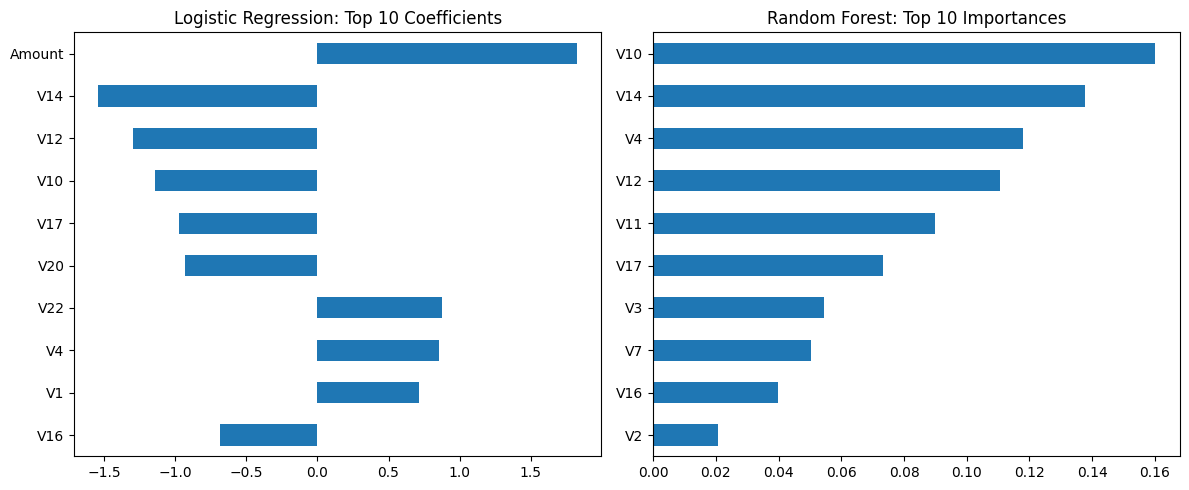

In [27]:
feature_names = X_train.columns

# Logistic Regression: the 10 largest coefficients (positive or negative)
coef = pd.Series(log_reg.coef_[0], index=feature_names)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)

# Random Forest: the 10 most important features
importance = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
top_imp = importance.head(10)

print("Logistic Regression, top 10 coefficients:")
print(top_coef.round(3))
print()
print("Random Forest, top 10 importances:")
print(top_imp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

top_coef[::-1].plot(kind="barh", ax=axes[0])
axes[0].set_title("Logistic Regression: Top 10 Coefficients")

top_imp[::-1].plot(kind="barh", ax=axes[1])
axes[1].set_title("Random Forest: Top 10 Importances")

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

Six features are in the top 10 of both models: V14, V12, V10, V17, V4 and V16. These probably carry most of the fraud signal, but they are anonymous, so I cannot say what they mean. In Logistic Regression, negative coefficients on V14, V12, V10 and V17 mean that lower values push a transaction towards fraud. Amount has the largest coefficient (1.83), but only Amount was scaled, so coefficient sizes are not directly comparable across features. Amount is not in the Random Forest top 10. Random Forest importances show how much a feature is used, not which direction it pushes.

In [21]:
import time
# time scoring the whole test set 5 times for each model and keep the median
for name, model in models.items():
    times = []
    for _ in range(5):
        start = time.perf_counter()
        model.predict_proba(X_test)
        times.append(time.perf_counter() - start)
    median_seconds = sorted(times)[2]
    print(name, "| median seconds:", round(median_seconds, 3),
          "| transactions per second:", round(len(X_test) / median_seconds),
          "| slowest run:", round(max(times), 3))

print()
print("1 million per hour is about", round(1_000_000 / 3600), "transactions per second")

# time scoring one transaction at a time (200 times) to see the delay per transaction
one_row = X_test.iloc[[0]]
for name, model in models.items():
    start = time.perf_counter()
    for _ in range(200):
        model.predict_proba(one_row)
    ms = (time.perf_counter() - start) / 200 * 1000
    print(name, "| milliseconds per single transaction:", round(ms, 2))

Logistic Regression | median seconds: 0.017 | transactions per second: 3356262 | slowest run: 0.029
Random Forest | median seconds: 0.165 | transactions per second: 343631 | slowest run: 0.191

1 million per hour is about 278 transactions per second
Logistic Regression | milliseconds per single transaction: 3.49
Random Forest | milliseconds per single transaction: 76.71


## Scalability
1 million transactions per hour is about 278 per second. I timed both models on the test set of 56,746 transactions, taking the middle of 5 runs. In a batch, Logistic Regression scored about 3.4 million transactions per second and Random Forest about 340,000, far above 278. Scoring one transaction at a time is much slower: 3.49 ms for Logistic Regression (about 287 per second) and 76.71 ms for Random Forest (about 13 per second). So one at a time, Logistic Regression would barely keep up and Random Forest would not, and it would need about 22 copies side by side or small batches. The timings change between runs on my laptop (an earlier run was about twice as fast), so they are rough. They only cover the scoring step and leave out reading the data, preparing the features, network delays and busy peak hours, which I did not test. The model would also need retraining as fraud patterns change.

## Error Analysis
I look at the 21 frauds that Random Forest missed and the 22 normal transactions it highlighted, to see if there is a pattern.

In [22]:
# predictions from both models
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]
lr_pred = log_reg.predict(X_test)

# frauds that Random Forest missed
missed_rf = ((y_test == 1) & (rf_pred == 0)).values
print("Frauds missed by Random Forest:", missed_rf.sum())
print("Of these, caught by Logistic Regression:", (lr_pred[missed_rf] == 1).sum())
print()

# amount and fraud probability for each missed fraud
missed_table = pd.DataFrame({
    "Amount": df_clean.loc[y_test.index[missed_rf], "Amount"],
    "RF_fraud_probability": rf_proba[missed_rf].round(3)
}).sort_values("RF_fraud_probability", ascending=False)
print(missed_table)

# amounts of the false alarms
false_rf = ((y_test == 0) & (rf_pred == 1)).values
print()
print("Random Forest false alarms:", false_rf.sum())
print(df_clean.loc[y_test.index[false_rf], "Amount"].describe().round(2))

Frauds missed by Random Forest: 21
Of these, caught by Logistic Regression: 9

         Amount  RF_fraud_probability
240222     1.00                 0.476
6971    1809.68                 0.425
87354     19.04                 0.423
10484      3.79                 0.342
195383   723.21                 0.212
68320      0.76                 0.188
231978     8.00                 0.134
58761      1.00                 0.105
68067    519.90                 0.077
145800   451.27                 0.073
56703      0.76                 0.062
52521    105.99                 0.054
249239  1096.99                 0.052
108258     0.76                 0.045
274382     0.00                 0.042
100623   549.06                 0.040
101509   320.00                 0.023
72757      1.79                 0.017
131272     0.20                 0.012
68633      1.18                 0.008
154286     0.92                 0.008

Random Forest false alarms: 22
count     22.00
mean     123.01
std      190.60
min  


Random Forest missed 21 frauds. Logistic Regression caught 9 of them, and the other 12 were missed by both models. Most of the misses looked normal to the forest, and 13 of them got a fraud probability under 0.1. Twelve had small amounts (under 10), but five big ones (all over 500) make up about 84% of the missed money. Only 3 had a probability above 0.4. The 22 false alarms have a median amount of 89.99, against 22.00 for normal transactions overall, but 22 cases is too few to say much.

In [23]:
# Random Forest at different cut offs (test set, for illustration only)
for cutoff in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (rf_proba >= cutoff).astype(int)
    caught = ((y_test.values == 1) & (pred == 1)).sum()
    false_alarms = ((y_test.values == 0) & (pred == 1)).sum()
    print("Cut off:", cutoff, "| frauds caught:", caught, "of", y_test.sum(),
          "| false alarms:", false_alarms,
          "| precision:", round(caught / (caught + false_alarms), 3))

Cut off: 0.5 | frauds caught: 74 of 95 | false alarms: 22 | precision: 0.771
Cut off: 0.4 | frauds caught: 77 of 95 | false alarms: 38 | precision: 0.67
Cut off: 0.3 | frauds caught: 78 of 95 | false alarms: 84 | precision: 0.481
Cut off: 0.2 | frauds caught: 79 of 95 | false alarms: 229 | precision: 0.256
Cut off: 0.1 | frauds caught: 82 of 95 | false alarms: 1210 | precision: 0.063


## Changing the Cut Off
I tried lower cut offs for Random Forest. At 0.4 it catches 3 more frauds (77 of 95) for 16 more false alarms. Below that the false alarms grow fast, and at 0.1 it catches 82 of 95 but flags 1,210 normal transactions. I used the test set to do this, so it is only a rough guide and my results above stay at 0.5. Most of the extra money caught at 0.4 comes from one transaction of 1,809.68.

## Conclusion
Only about 0.17% of the transactions are fraud. I judged the models on precision, recall, F1, AUC-ROC and AUPRC instead. Logistic Regression highlighted more frauds (83 of 95 against 74) but gave 1,408 false alarms, while Random Forest gave only 22. Random Forest also had the better F1 (0.77 against 0.10) and AUPRC (0.781 against 0.672), so I would pick it.